# Market-anomaly replications: evidence walkthrough

Three published intraday effects, re-tested on retail CFD data with realistic per-event costs.
Everything here reads saved results; no broker data is needed.

In [1]:
import json, sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "figures"))
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.width", 140)

## 01 · FX fixing reversal (Krohn, Mueller & Whelan, *Journal of Finance* 2024)

Daily two-leg trade around the fix: short EURUSD from 02:00 NY into the fix, long after it until 17:00.
With mid prices $m_k$ at the three boundaries, gross P&L per day in pips is
$g_t = 10^4\,[(m_0-m_1) + (m_2-m_1)]$, tested against zero with a standard t-statistic.
The executable version (`exec`) fills at bid/ask, so each leg pays its own spread at that moment.

In [2]:
rows = {}
for leg in ["ecb", "london"]:
    d = pd.read_csv(ROOT / "01-fx-fixing-reversal" / "results" / f"legs_{leg}.csv")
    for col in ["gross", "exec"]:
        x = d[col] * 1e4
        rows[(leg, col)] = dict(n=len(x), mean_pips=x.mean(), t=x.mean() / (x.std(ddof=1) / np.sqrt(len(x))))
pd.DataFrame(rows).T

n  mean_pips       t
ecb    gross 1,170.0000    -0.4309 -0.3123
       exec  1,170.0000    -2.8694 -2.0745
london gross 1,170.0000     0.0409  0.0301
       exec  1,170.0000    -2.3964 -1.7598

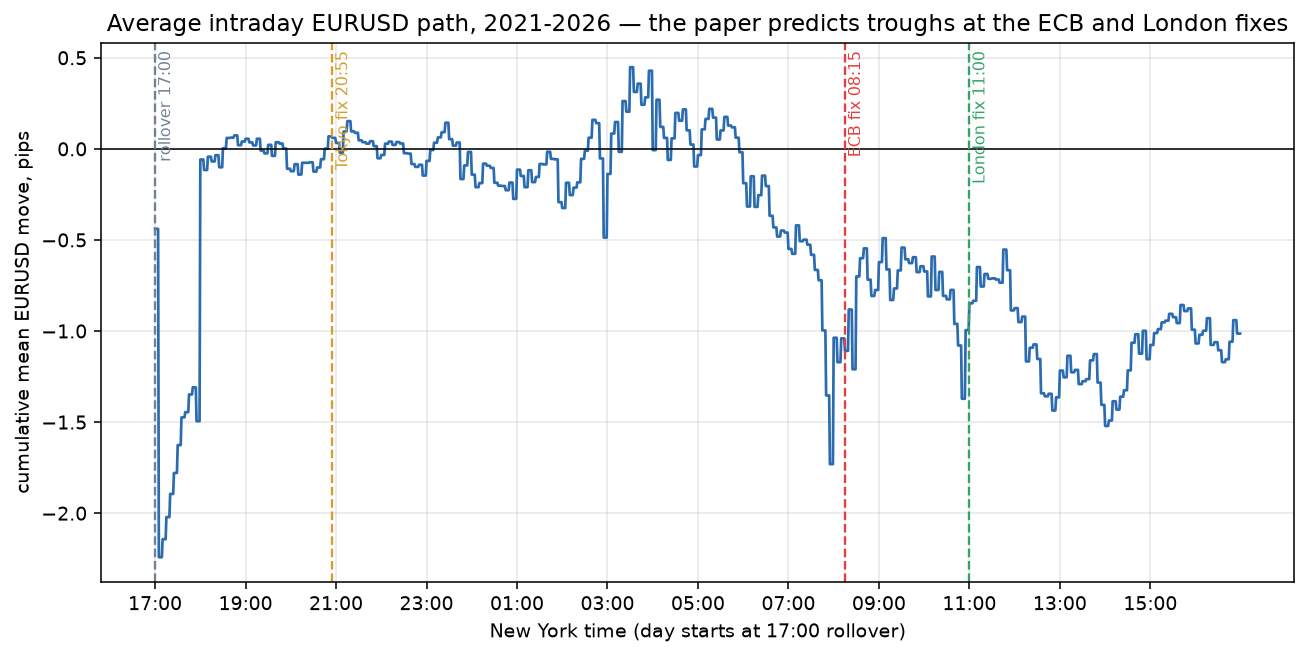

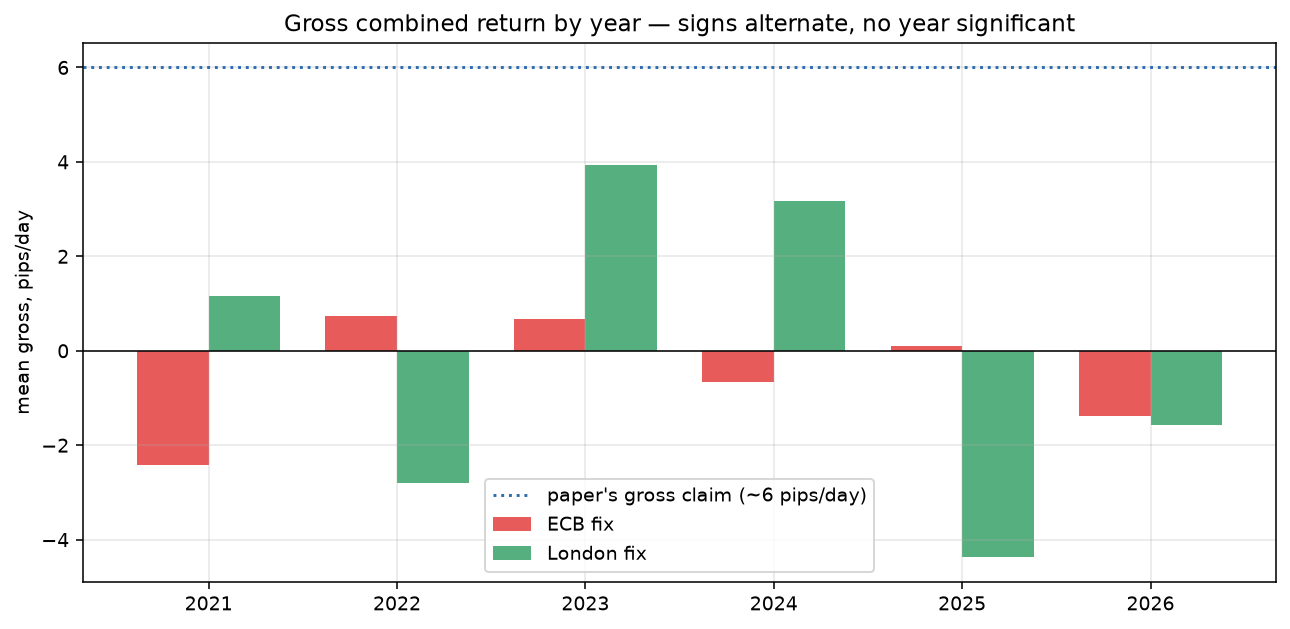

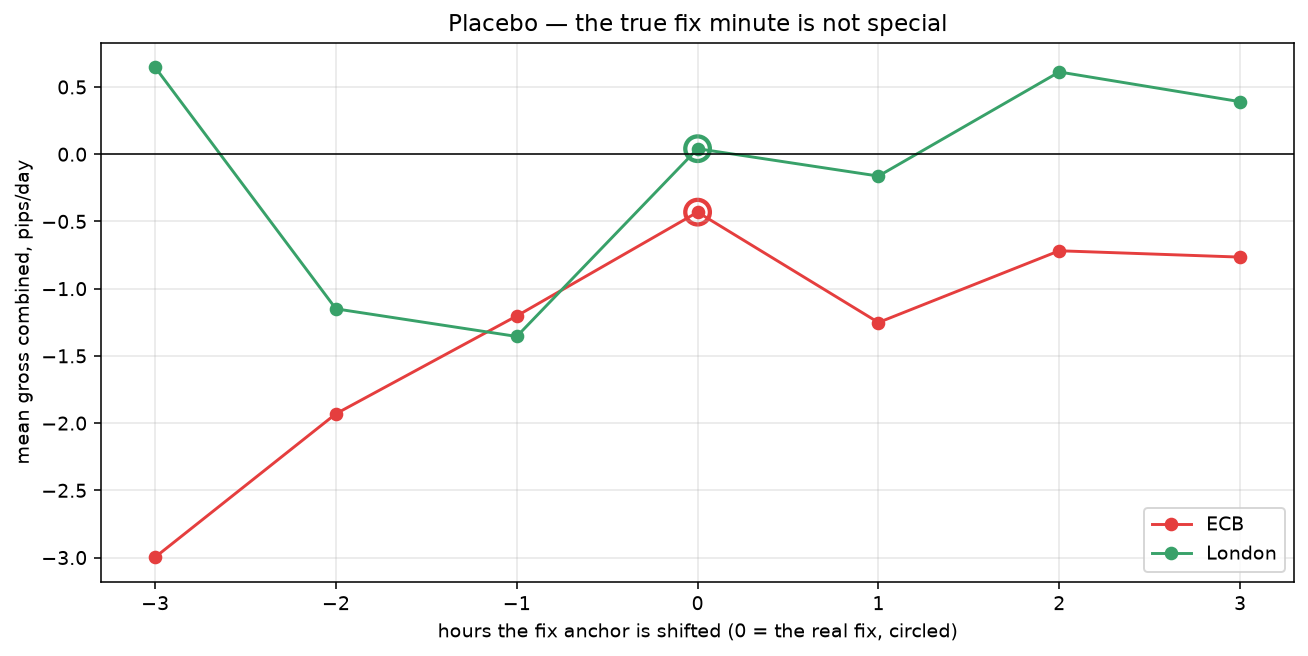

In [3]:
for f in ["01_intraday_path", "02_by_year", "06_placebo"]:
    display(Image(filename=str(ROOT / "01-fx-fixing-reversal" / "figs" / f"{f}.png"), width=760))

## 02 · Overnight–intraday reversal (Della Corte et al. 2022)

A high win rate means nothing on its own: it can be bought by placing a near target and a far stop.
With payoff ratio $\rho = \overline{\text{win}}/\overline{|\text{loss}|}$, the break-even win rate is
$\mathrm{WR}_0 = 1/(1+\rho)$, since expectancy $\mathrm{WR}\,\rho - (1-\mathrm{WR}) = 0$ there.
**Edge** is realised win rate minus $\mathrm{WR}_0$, so a positive edge means positive expectancy.

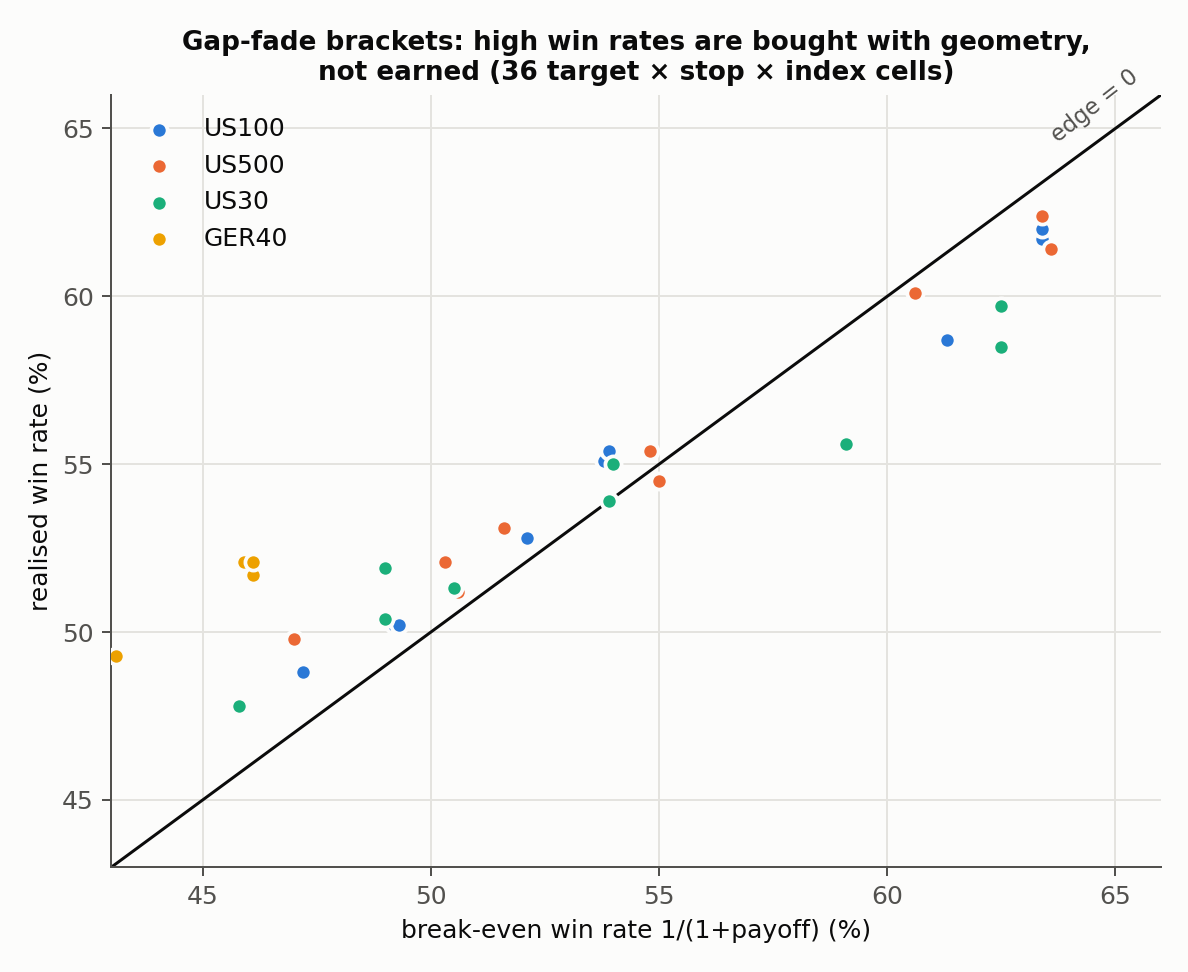

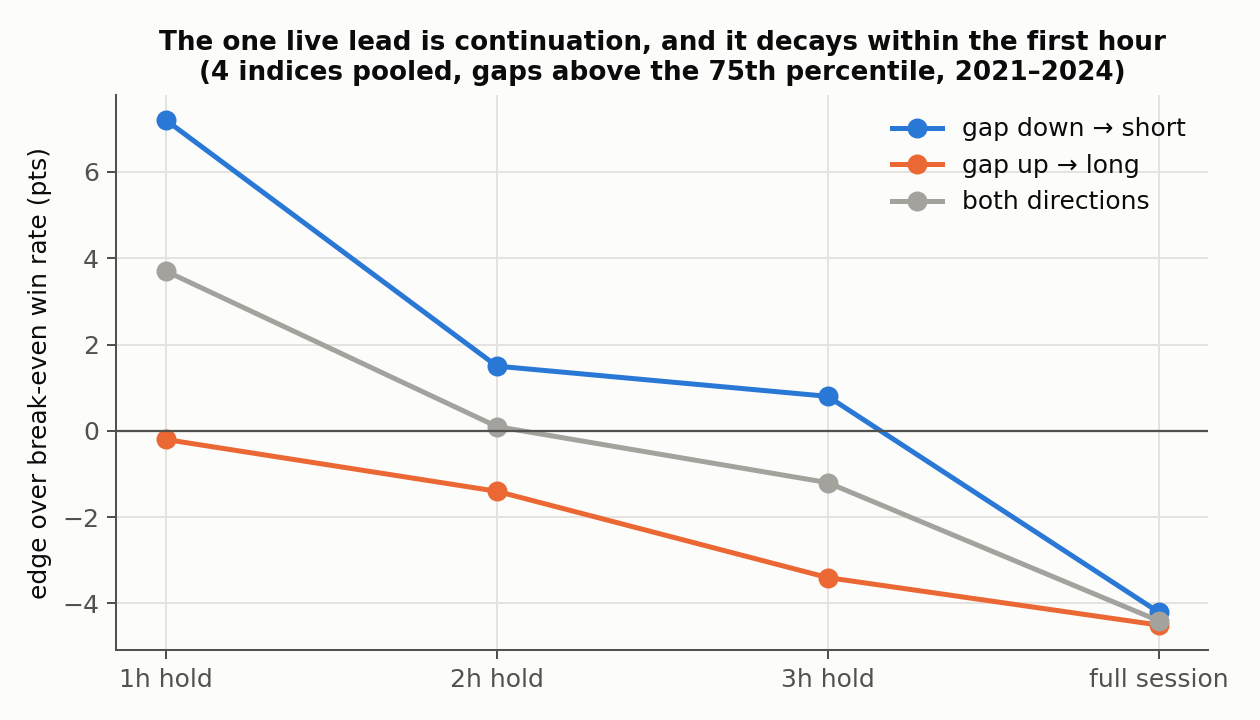

In [4]:
import make_figures as mf
mf.fig_geometry(); mf.fig_continuation_decay()
for f in ["02_winrate_vs_geometry", "02_gap_continuation_decay"]:
    display(Image(filename=str(ROOT / "figures" / f"{f}.png"), width=700))

## 03 · Displacement, Gao et al. (2018) intraday momentum

Gao et al. regress the last half-hour return on the first and second-to-last:
$r_{n,t} = \alpha + \beta_1 r_{1,t} + \beta_2 r_{n-1,t} + \varepsilon_t$.

In [5]:
g = pd.read_csv(ROOT / "03-displacement-and-intraday-momentum" / "results" / "stage4_gao.csv")
g[["symbol", "n_days", "beta_r1", "t_r1", "beta_rnm1", "t_rnm1", "holdout_t_r1", "holdout_t_rnm1", "n_holdout"]]

,symbol,n_days,beta_r1,t_r1,beta_rnm1,t_rnm1,holdout_t_r1,holdout_t_rnm1,n_holdout
0,US100.cash,1202,-0.0191,-1.1289,0.0810,2.7574,-0.4011,-0.8086,389
1,US500.cash,1202,-0.0387,-1.7811,0.0847,2.6556,-0.1816,-1.1862,389
2,US30.cash,1378,-0.0437,-2.4962,0.0605,2.0284,-1.1908,-1.3776,389
3,GER40.cash,1076,-0.0083,-0.5237,0.0947,3.5694,-0.8237,2.2831,365
4,XAUUSD,1386,-0.0041,-0.3931,-0.0051,-0.2348,-1.2575,-1.2253,391
5,EURUSD,1439,-0.0033,-0.3069,-0.0680,-3.1645,0.2946,-4.4860,407
6,GBPJPY,1850,-0.0180,-1.8376,-0.0266,-1.3061,-0.8491,-1.2922,410


Development-sample vs holdout for every displacement specification (Newey–West t-statistics,
lag = holding horizon):

$$t_{NW} = \frac{\bar x}{\sqrt{\hat\sigma^2_{NW}/n}}, \qquad
\hat\sigma^2_{NW} = \hat\gamma_0 + 2\sum_{\ell=1}^{L}\Big(1-\frac{\ell}{L+1}\Big)\hat\gamma_\ell$$

150 specs, 19 significant in development, 0 survive the holdout


,label,symbol,n,gross_atr,cost_mean,net_atr,net_t
0,post-close reversion,GBPJPY,2964,0.5589,1.2917,-0.7328,-14.1039
1,post-close reversion,EURUSD,2306,0.2191,0.4698,-0.2507,-6.4891
2,NY-close reversion,GBPJPY,1482,0.2481,0.1793,0.0688,0.8753
3,post-close reversion,US30.cash,1124,0.0821,0.0618,0.0203,0.4998
4,post-close reversion,GER40.cash,810,0.1895,0.5642,-0.3747,-5.4371


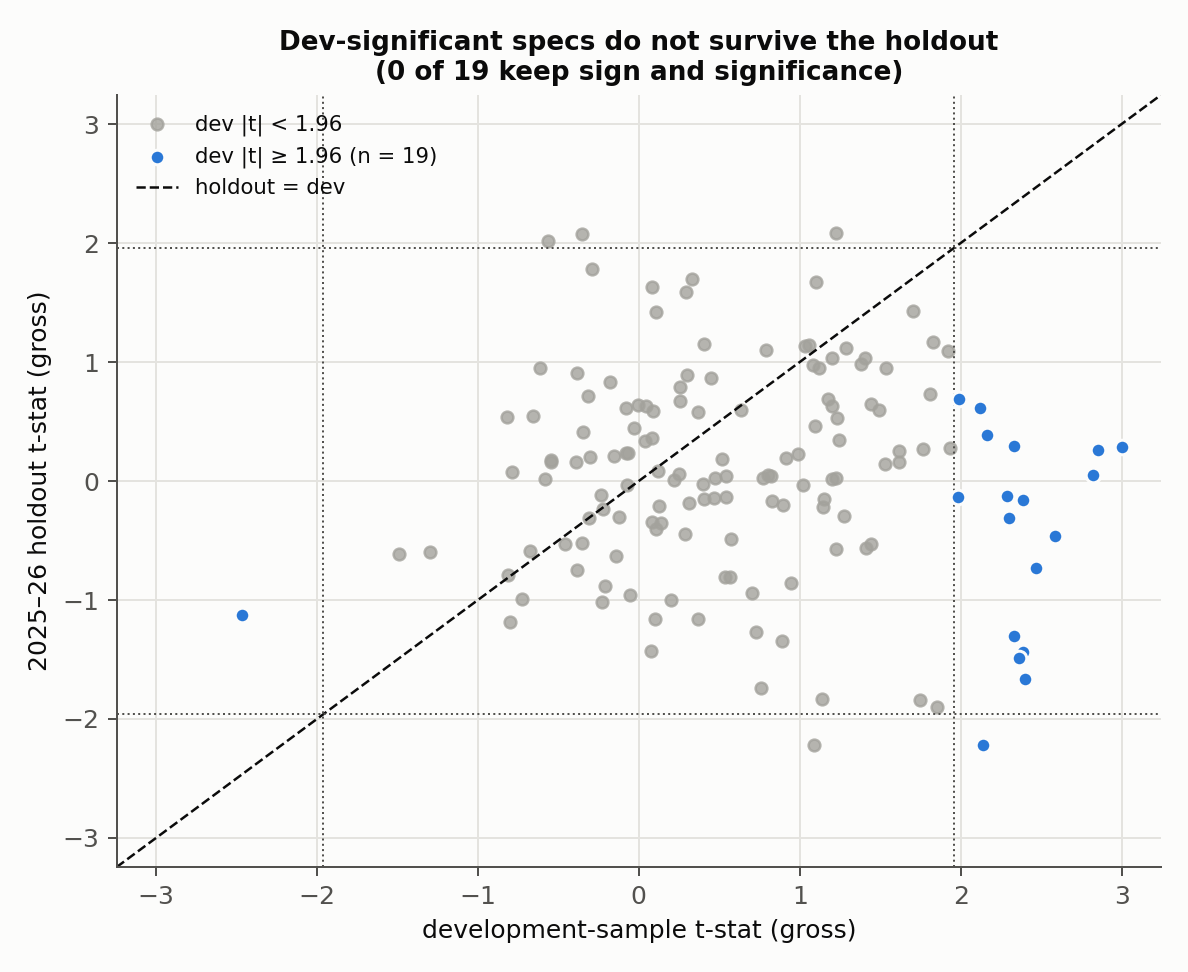

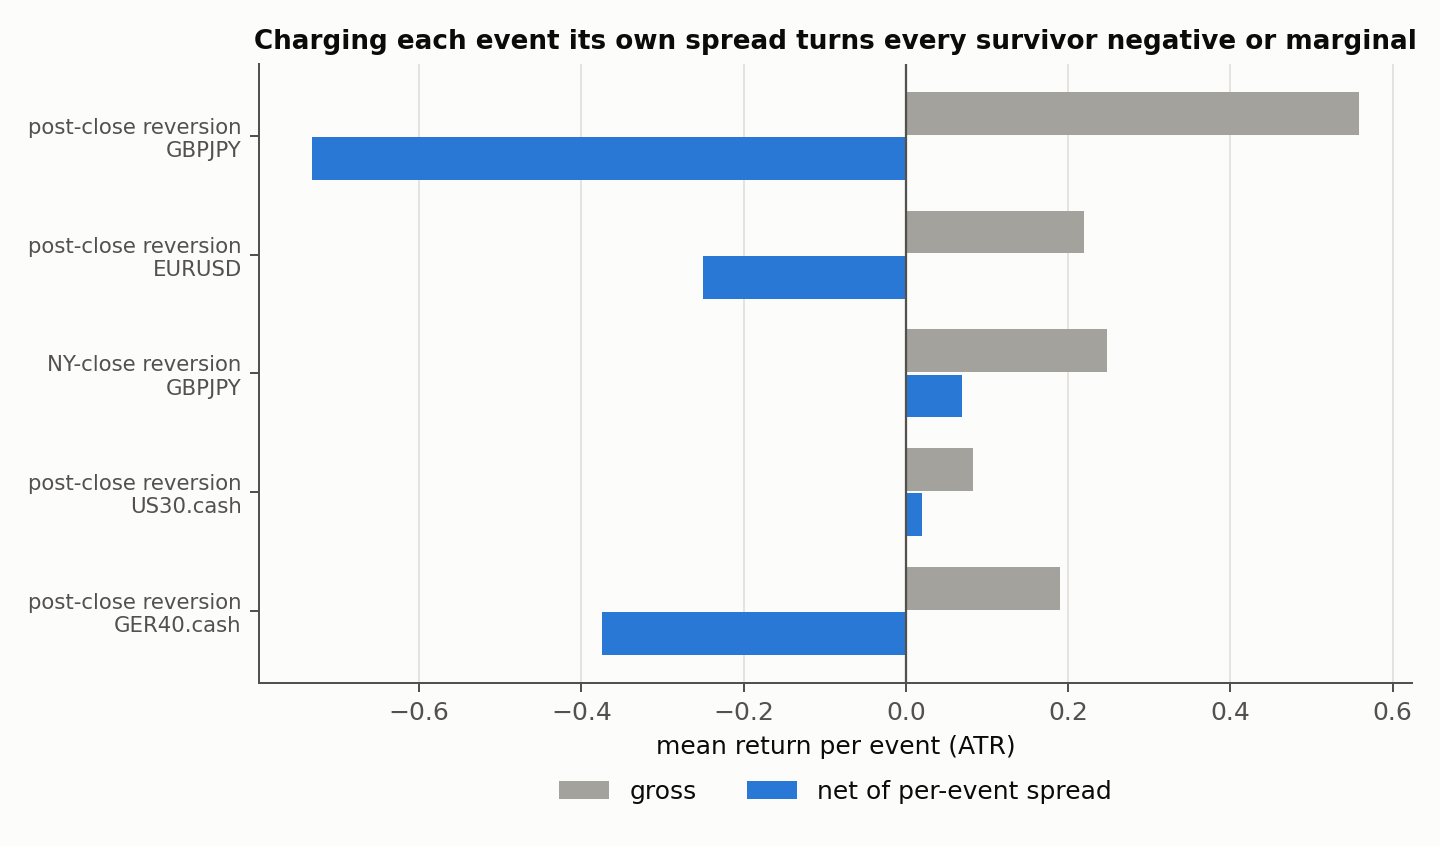

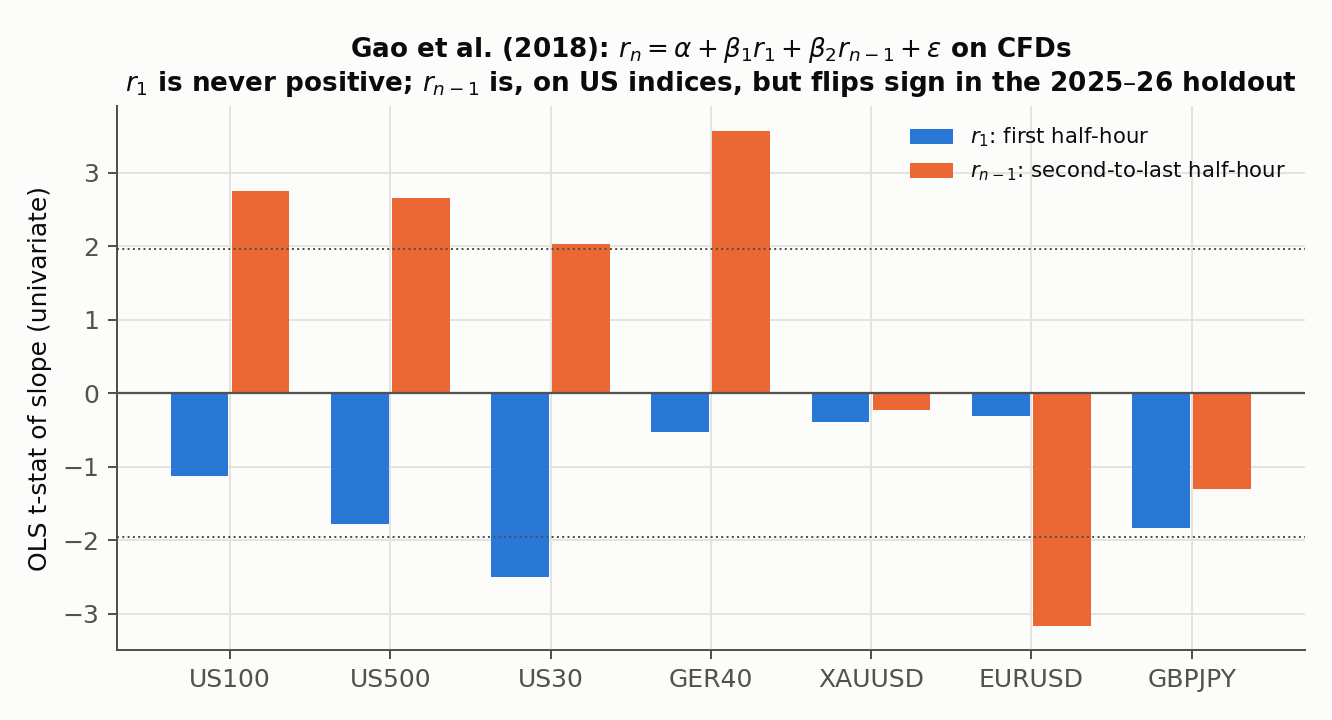

In [6]:
s = pd.read_csv(ROOT / "03-displacement-and-intraday-momentum" / "results" / "stage4_sweep.csv")
sig = s[s.dev_t.abs() >= 1.96]
print(f"{len(s)} specs, {len(sig)} significant in development, "
      f"{((np.sign(sig.dev_t) == np.sign(sig.hold_t)) & (sig.hold_t.abs() >= 1.96)).sum()} survive the holdout")
c = pd.read_csv(ROOT / "03-displacement-and-intraday-momentum" / "results" / "stage6_costed.csv")
display(c[["label", "symbol", "n", "gross_atr", "cost_mean", "net_atr", "net_t"]])
mf.fig_dev_vs_holdout(); mf.fig_costs(); mf.fig_gao()
for f in ["03_dev_vs_holdout", "03_gross_vs_net", "03_gao_replication"]:
    display(Image(filename=str(ROOT / "figures" / f"{f}.png"), width=720))